In [107]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [108]:
SPECTRUM_RESULTS_DIR = Path.cwd().resolve().parents[2] / "results" / "spectrum"  # notebook lives in sw/tools/notebooks/

Plotting functions

In [109]:
import mplcursors

_hover_cursors = []


def _enable_hover(ax):
    """Enable mouse-over annotations for all artists in an axes."""
    cursor = mplcursors.cursor(ax, hover=True)

    @cursor.connect("add")
    def _on_add(selection):
        x, y = selection.target
        selection.annotation.set_text(f"x: {x:.6g}\ny: {y:.6g}")

    _hover_cursors.append(cursor)


def plot_phase_noise(traces_csv):
    df = pd.read_csv(traces_csv)
    df_l_trace = df[df["kind"] == "L_trace"]

    fig, ax = plt.subplots(figsize=(10, 6))

    group_cols = ["cfg_idx", "set_current", "set_c1", "set_c2", "set_r1"]
    for cfg_vals, group in df_l_trace.groupby(group_cols):
        idx, i, c1, c2, r1 = cfg_vals
        label = f"Cfg {idx} | I={i}, C1={c1}, C2={c2}, R1={r1}"
        ax.plot(group["freq"], group["level_dbm"], label=label, linewidth=1.5)

    ax.set_xscale("log")
    ax.set_xlabel("Offset Frequency (Hz)")
    ax.set_ylabel("Phase Noise (dBc/Hz)")
    ax.set_title("PLL Output Phase Noise Profile")
    ax.grid(True, which="both", linestyle="--", alpha=0.6)
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    fig.tight_layout()

    _enable_hover(ax)
    plt.show()

def plot_phase_noise_div(traces_csv):
    df = pd.read_csv(traces_csv)
    df_l_trace = df[df["kind"] == "L_trace"]

    fig, ax = plt.subplots(figsize=(10, 6))

    group_cols = ["cfg_idx", "set_current", "set_c1", "set_c2", "set_r1", "set_div_freq"]
    for cfg_vals, group in df_l_trace.groupby(group_cols):
        idx, i, c1, c2, r1, div = cfg_vals
        label = f"Cfg {idx} | I={i}, C1={c1}, C2={c2}, R1={r1}, Div={div}"
        ax.plot(group["freq"], group["level_dbm"], label=label, linewidth=1.5)

    ax.set_xscale("log")
    ax.set_xlabel("Offset Frequency (Hz)")
    ax.set_ylabel("Phase Noise (dBc/Hz)")
    ax.set_title("PLL Output Phase Noise Profile")
    ax.grid(True, which="both", linestyle="--", alpha=0.6)
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    fig.tight_layout()

    _enable_hover(ax)
    plt.show()


def plot_output_spectrum(traces_csv):
    """
    Plots the averaged wide spectrum around the carrier.
    """
    df = pd.read_csv(traces_csv)
    df_spectrum = df[df["kind"] == "spectrum"]

    fig, ax = plt.subplots(figsize=(10, 6))

    group_cols = ["cfg_idx", "set_current", "set_c1", "set_c2", "set_r1"]
    for cfg_vals, group in df_spectrum.groupby(group_cols):
        idx, i, c1, c2, r1 = cfg_vals
        label = f"Cfg {idx} | I={i}, C1={c1}, C2={c2}, R1={r1}"
        ax.plot(group["freq"] / 1e6, group["level_dbm"], label=label)

    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("Power (dBm)")
    ax.set_title("Averaged Output Spectrum")
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    fig.tight_layout()

    _enable_hover(ax)
    plt.show()


def plot_jitter_comparison(results_csv):
    """
    Creates a bar chart comparing the integrated RMS time jitter across configurations.
    """
    df = pd.read_csv(results_csv)
    
    # Create a unified label for each configuration run
    df['config_label'] = df.apply(
        lambda r: f"Cfg {r['cfg_idx']}\n(I={r['set_current']}, C1={r['set_c1']}, C2={r['set_c2']}, R1={r['set_r1']}, Div={r['set_div_freq']})", 
        axis=1
    )
    
    plt.figure(figsize=(8, 6))
    sns.barplot(data=df, x='config_label', y='time_jitter_trace_ps', palette='viridis')
    
    plt.xlabel('Configuration')
    plt.ylabel('RMS Time Jitter (ps)')
    plt.title('Integrated RMS Time Jitter Comparison')
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

def lowest_jitter_config(file_list):
    """
    Given a list of CSV files, this function identifies the configuration with the lowest RMS time jitter.
    
    Args:
        file_list (list): List of CSV file paths containing PLL measurement results.

    Returns:
        dict: A dictionary containing the configuration parameters corresponding to the lowest jitter.
    """

    dataframes = []
    for file_path in file_list:
        try:
            df = pd.read_csv(file_path)
            if 'time_jitter_trace_ps' in df.columns:
                dataframes.append(df)
            else:
                print(f"Warning: Target metric missing in {file_path}. Skipping.")
        except Exception as e:
            print(f"Error reading {file_path}: {e}")

    if not dataframes:
        raise ValueError("No valid data could be loaded.")        

    master_df = pd.concat(dataframes, ignore_index=True)

    # Find the row with the minimum jitter
    best_idx = master_df['time_jitter_trace_common_ps'].idxmin()
    best_row = master_df.loc[best_idx]

    # Extract the configuration
    target_cols = [
        "set_current", "set_c1", "set_c2", "set_r1", 
        "vco_tune_coarse", "vco_current_min", "vco_current_max", 
        "set_div_freq", "f_out", "f_vco_meas", 
        "time_jitter_trace_common_ps"  # Including the metric itself for reference
    ]
    
    # Filter to ensure we only request columns that actually exist to prevent KeyErrors
    available_cols = [col for col in target_cols if col in master_df.columns]
    
    return best_row[available_cols].to_dict()
    

def analyze_pll_csv(file_path):
    # Load the data
    df = pd.read_csv(file_path)
    
    # Identify which configuration setting is being swept (e.g., set_c2 changes from 0 to 7)
    # This helps label the X-axis for grouped runs
    sweep_param = 'set_c2' if 'set_c2' in df.columns else 'cfg_idx'
    x_labels = [f"Run {i}\n({sweep_param}:{val})" for i, val in enumerate(df[sweep_param])]
    x_pos = np.arange(len(df))

    # Initialize the dashboard
    fig, axs = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle('PLL Measurement Dashboard', fontsize=16, fontweight='bold')

    # ==========================================
    # 1. Jitter Breakdown (Top Left)
    # ==========================================
    ax_jitter = axs[0, 0]
    width = 0.25
    
    ax_jitter.bar(x_pos - width, df['time_jitter_trace_ps'], width=width, label='Total RMS', color='#1f77b4')
    ax_jitter.bar(x_pos, df['time_jitter_noise_ps'], width=width, label='Noise Contrib.', color='#ff7f0e')
    ax_jitter.bar(x_pos + width, df['time_jitter_spur_ps'], width=width, label='Spur Contrib.', color='#d62728')
    
    ax_jitter.set_xticks(x_pos)
    ax_jitter.set_xticklabels(x_labels)
    ax_jitter.set_ylabel('Jitter (ps)')
    ax_jitter.set_title('Jitter Performance per Configuration')
    ax_jitter.legend()
    ax_jitter.grid(axis='y', linestyle='--', alpha=0.6)

    # ==========================================
    # 2. Phase Noise Profile (Top Right)
    # ==========================================
    ax_pn = axs[0, 1]
    
    # Extract L_out_* columns dynamically and sort them by offset frequency
    pn_cols = [c for c in df.columns if c.startswith('L_out_')]
    pn_data = []
    for c in pn_cols:
        try:
            offset = int(c.split('_')[-1])
            pn_data.append((offset, c))
        except ValueError:
            pass
            
    pn_data.sort(key=lambda x: x[0])
    offsets = [x[0] for x in pn_data]
    ordered_pn_cols = [x[1] for x in pn_data]

    for i, row in df.iterrows():
        pn_values = pd.to_numeric(row[ordered_pn_cols], errors='coerce')
        ax_pn.semilogx(offsets, pn_values, marker='o', markersize=4, 
                       label=f'Run {i} ({sweep_param}={row[sweep_param]})')

    ax_pn.set_xlabel('Offset Frequency (Hz)')
    ax_pn.set_ylabel('Phase Noise (dBc/Hz)')
    ax_pn.set_title('Phase Noise (L_out)')
    ax_pn.legend()
    ax_pn.grid(True, which="both", ls="-", alpha=0.3)

    # ==========================================
    # 3. Power Consumption (Bottom Left)
    # ==========================================
    ax_pwr = axs[1, 0]
    
    # Convert PLL power from Watts to milliwatts
    pll_p_mw = df['pll_p'] * 1000 
    
    ax_pwr.plot(x_pos, pll_p_mw, marker='s', color='#2ca02c', linewidth=2, markersize=8)
    ax_pwr.set_xticks(x_pos)
    ax_pwr.set_xticklabels(x_labels)
    ax_pwr.set_ylabel('Power (mW)')
    ax_pwr.set_title('PLL Power Consumption')
    ax_pwr.grid(axis='y', linestyle='--', alpha=0.6)
    
    # Add data labels to the power plot for quick reading
    for i, pwr in enumerate(pll_p_mw):
        ax_pwr.annotate(f'{pwr:.2f}', (i, pwr), textcoords="offset points", xytext=(0,10), ha='center')

    # ==========================================
    # 4. Spur Distribution (Bottom Right)
    # ==========================================
    ax_spur = axs[1, 1]
    
    # Parse the semicolon-separated spur strings
    for i, row in df.iterrows():
        spurs_str = str(row['spurs'])
        if pd.isna(spurs_str) or spurs_str == 'nan':
            continue
            
        freqs, levels = [], []
        for spur in spurs_str.split(';'):
            try:
                f_part, p_part = spur.split(':')
                freqs.append(float(f_part.replace('Hz', '').strip()))
                levels.append(float(p_part.replace('dBc', '').strip()))
            except ValueError:
                continue
                
        if freqs:
            ax_spur.scatter(freqs, levels, label=f'Run {i}', alpha=0.7, s=30)

    ax_spur.set_xscale('log')
    ax_spur.set_xlabel('Spur Frequency (Hz)')
    ax_spur.set_ylabel('Amplitude (dBc)')
    ax_spur.set_title('Spur Landscape')
    ax_spur.legend()
    ax_spur.grid(True, which="both", ls="-", alpha=0.3)

    # Render
    plt.tight_layout()
    plt.show()

def print_csv_fully_visible(file_path, display_format='list'):
    """
    Prints a wide CSV file in a human-readable format.
    
    Args:
        file_path (str): Path to the CSV file.
        display_format (str): 'list' for vertical key-value pairs, 
                              'table' to force a wide, untruncated grid.
    """
    df = pd.read_csv(file_path)
    
    if display_format == 'list':
        # Prints each row as a block, eliminating horizontal scrolling issues
        for index, row in df.iterrows():
            print(f"========== RECORD {index} ==========")
            for col_name, value in row.items():
                # Aligns the column names to the left with a fixed width of 30 characters
                print(f"{col_name:<30} | {value}")
            print("\n")
            
    elif display_format == 'table':
        # Temporarily overrides pandas display limits to show all data
        with pd.option_context(
            'display.max_rows', None,
            'display.max_columns', None,
            'display.width', 2000,          # Extends terminal wrap width
            'display.max_colwidth', None    # Prevents long strings (like your 'spurs' column) from truncating
        ):
            print(df)

## Configuration 1

$f_{ref} = 75\text{ MHz} \rightarrow f_{VCO} = 9.6\text{ GHz}; K_{VCO, predicted} \approx 32.3\text{ GHz/V}$

In [110]:
TRACES_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_162412_traces.csv"
RESULTS_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_162412.csv"

df_results = pd.read_csv(RESULTS_CSV)
print("Scalar Results Columns:\n", df_results.columns.tolist())

df_traces = pd.read_csv(TRACES_CSV)
print("\nTraces Columns:\n", df_traces.columns.tolist())
print("\nTrace Kinds:", df_traces['kind'].unique())

Scalar Results Columns:
 ['time', 'cfg_idx', 'fb_clk_oen', 'pll_clk_o_en', 'clk_div_val', 'clk_div_en', 'pdown_PD', 'pdown_VCO', 'vco_tune_coarse', 'vco_current_min', 'vco_current_max', 'set_v_ctrl', 'set_clk_out', 'set_div_freq', 'set_fb_mux', 'set_current', 'set_c1', 'set_c2', 'set_r1', 'f_out', 'f_pll_out', 'pll_div', 'ext_div', 'offset_max', 'f_out_meas', 'f_vco_meas', 'n_meas', 'divider_ok', 'carrier_dbm', 'n_averages', 'time_jitter_ps', 'phase_jitter_out_mrad', 'phase_jitter_pll_mrad', 'phase_jitter_vco_mrad', 'time_jitter_trace_ps', 'phase_jitter_trace_out_mrad', 'time_jitter_noise_ps', 'time_jitter_spur_ps', 'n_spurs', 'spurs', 'common_band', 'time_jitter_common_ps', 'time_jitter_trace_common_ps', 'detector', 'average_type', 'L_out_1000', 'L_out_10000', 'L_out_100000', 'L_out_1000000', 'L_out_10000000', 'L_out_50000000', 'L_pll_1000', 'L_pll_10000', 'L_pll_100000', 'L_pll_1000000', 'L_pll_10000000', 'L_pll_50000000', 'L_vco_1000', 'L_vco_10000', 'L_vco_100000', 'L_vco_1000000',

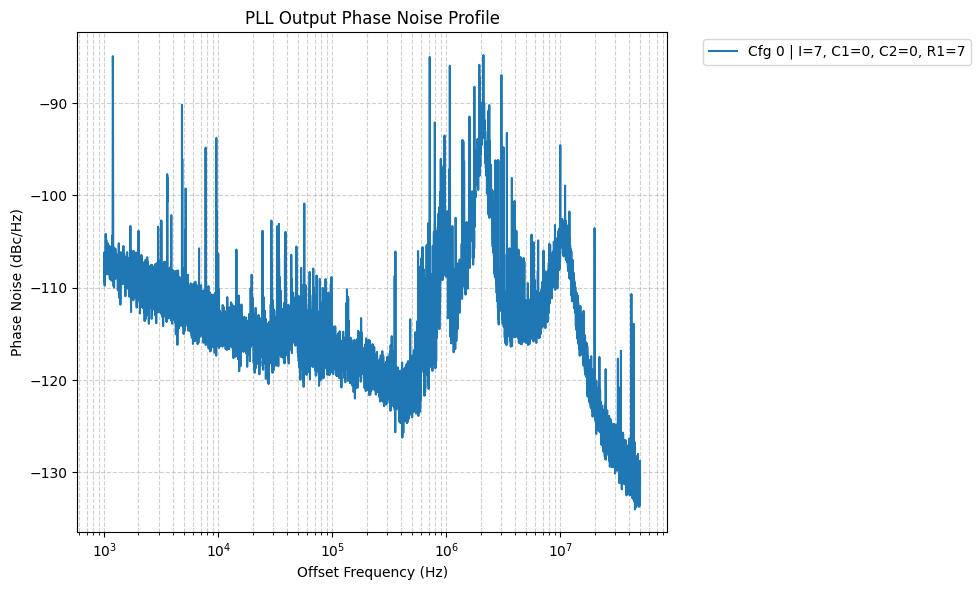

In [111]:
plot_phase_noise(TRACES_CSV)

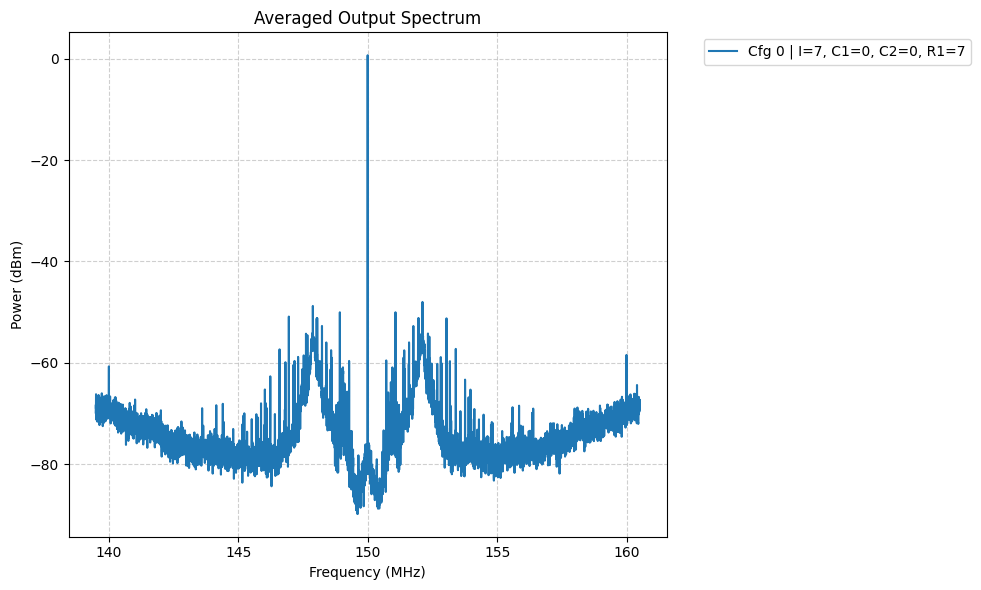

In [112]:
plot_output_spectrum(TRACES_CSV)

/tmp/ipykernel_2157397/597911633.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='config_label', y='time_jitter_trace_ps', palette='viridis')


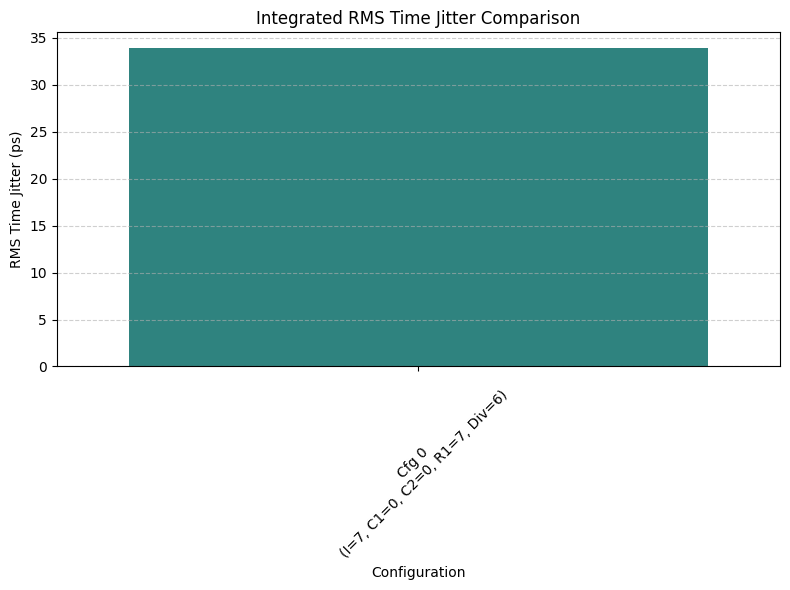

In [113]:
plot_jitter_comparison(RESULTS_CSV)

### Configuration Sweeps

In [114]:
TRACES1_ICP_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_163503_traces.csv"
RESULTS1_ICP_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_163503.csv"
TRACES1_R1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_164501_traces.csv"
RESULTS1_R1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_164501.csv"
TRACES1_C1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_165820_traces.csv"
RESULTS1_C1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_165820.csv"
TRACES1_C2_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_171138_traces.csv"
RESULTS1_C2_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_171138.csv"

In [115]:
config_sweeps = {
    "I_CP variation": (TRACES1_ICP_CSV, RESULTS1_ICP_CSV),
    "R1 variation": (TRACES1_R1_CSV, RESULTS1_R1_CSV),
    "C1 variation": (TRACES1_C1_CSV, RESULTS1_C1_CSV),
    "C2 variation": (TRACES1_C2_CSV, RESULTS1_C2_CSV),
}

lowest_jitter_config([RESULTS1_ICP_CSV, RESULTS1_R1_CSV, RESULTS1_C1_CSV, RESULTS1_C2_CSV])

{'set_current': 7,
 'set_c1': 0,
 'set_c2': 0,
 'set_r1': 7,
 'vco_tune_coarse': 0,
 'vco_current_min': 0,
 'vco_current_max': 2,
 'set_div_freq': 6,
 'f_out': 150000000.0,
 'f_vco_meas': 9599994361.6,
 'time_jitter_trace_common_ps': 33.76510923551806}

In [116]:
# Display traces
display_Icp = False
display_R1 = False
display_C1 = False
display_C2 = False

display_flags = {
    "I_CP variation": display_Icp,
    "R1 variation": display_R1,
    "C1 variation": display_C1,
    "C2 variation": display_C2,
}

for sweep_name, (traces_csv, results_csv) in config_sweeps.items():
    if not display_flags.get(sweep_name, False):
        continue

    print(f"Configuration 1 — {sweep_name}")

    plot_phase_noise(traces_csv)
    plot_output_spectrum(traces_csv)
    plot_jitter_comparison(results_csv)
    analyze_pll_csv(results_csv)
    print_csv_fully_visible(results_csv, display_format="list")

## Configuration 2

$f_{ref} = 37.5\text{ MHz} \rightarrow f_{VCO} = 4.8\text{ GHz}; K_{VCO, predicted} \approx 30.4\text{ GHz/V}$

### Configuration sweeps

In [ ]:
TRACES2_ICP_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_172850_traces.csv"
RESULTS2_ICP_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_172850.csv"
TRACES2_R1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_173530_traces.csv"
RESULTS2_R1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_173530.csv"
TRACES2_C1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_174423_traces.csv"
RESULTS2_C1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_174423.csv"
TRACES2_C2_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_175316_traces.csv"
RESULTS2_C2_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261009_175316.csv"

In [118]:
config_sweeps = {
    "I_CP variation": (TRACES2_ICP_CSV, RESULTS2_ICP_CSV),
    "R1 variation": (TRACES2_R1_CSV, RESULTS2_R1_CSV),
    "C1 variation": (TRACES2_C1_CSV, RESULTS2_C1_CSV),
    "C2 variation": (TRACES2_C2_CSV, RESULTS2_C2_CSV),
}

lowest_jitter_config([RESULTS2_ICP_CSV, RESULTS2_R1_CSV, RESULTS2_C1_CSV, RESULTS2_C2_CSV])

{'set_current': 7,
 'set_c1': 0,
 'set_c2': 0,
 'set_r1': 7,
 'vco_tune_coarse': 0,
 'vco_current_min': 8,
 'vco_current_max': 8,
 'set_div_freq': 6,
 'f_out': 75000000.0,
 'f_vco_meas': 4799997280.0,
 'time_jitter_trace_common_ps': 26.39645676345809}

In [119]:
# Display traces
display_Icp = False
display_R1 = False
display_C1 = False
display_C2 = False

display_flags = {
    "I_CP variation": display_Icp,
    "R1 variation": display_R1,
    "C1 variation": display_C1,
    "C2 variation": display_C2,
}

for sweep_name, (traces_csv, results_csv) in config_sweeps.items():
    if not display_flags.get(sweep_name, False):
        continue

    print(f"Configuration 1 — {sweep_name}")

    plot_phase_noise(traces_csv)
    plot_output_spectrum(traces_csv)
    plot_jitter_comparison(results_csv)
    analyze_pll_csv(results_csv)
    print_csv_fully_visible(results_csv, display_format="list")

### Adding ferrites to lower instrument noise

Exact same measurements as in the previous plots but adding more ferrites to the instruments.

In [120]:
TRACES2_ICP_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_132233_traces.csv"
RESULTS2_ICP_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_132233.csv"
TRACES2_R1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_132935_traces.csv"
RESULTS2_R1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_132935.csv"
TRACES2_C1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_133831_traces.csv"
RESULTS2_C1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_133831.csv"
TRACES2_C2_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_134726_traces.csv"
RESULTS2_C2_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_134726.csv"

In [121]:
config2_sweeps = {
    "I_CP variation": (TRACES2_ICP_CSV, RESULTS2_ICP_CSV),
    "R1 variation": (TRACES2_R1_CSV, RESULTS2_R1_CSV),
    "C1 variation": (TRACES2_C1_CSV, RESULTS2_C1_CSV),
    "C2 variation": (TRACES2_C2_CSV, RESULTS2_C2_CSV),
}

lowest_jitter_config([RESULTS2_ICP_CSV, RESULTS2_R1_CSV, RESULTS2_C1_CSV, RESULTS2_C2_CSV])

{'set_current': 7,
 'set_c1': 0,
 'set_c2': 0,
 'set_r1': 7,
 'vco_tune_coarse': 0,
 'vco_current_min': 8,
 'vco_current_max': 8,
 'set_div_freq': 6,
 'f_out': 75000000.0,
 'f_vco_meas': 4799997280.0,
 'time_jitter_trace_common_ps': 15.372889047868568}

In [122]:
# Display traces
display_Icp = False
display_R1 = False
display_C1 = False
display_C2 = False

display_flags = {
    "I_CP variation": display_Icp,
    "R1 variation": display_R1,
    "C1 variation": display_C1,
    "C2 variation": display_C2,
}

for sweep_name, (traces_csv, results_csv) in config_sweeps.items():
    if not display_flags.get(sweep_name, False):
        continue

    print(f"Configuration 1 — {sweep_name}")

    plot_phase_noise(traces_csv)
    plot_output_spectrum(traces_csv)
    plot_jitter_comparison(results_csv)
    analyze_pll_csv(results_csv)
    print_csv_fully_visible(results_csv, display_format="list")

Run #2 with the same parameters (assessing variability between measurements)

In [ ]:
TRACES2_ICP_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_135937_traces.csv"
RESULTS2_ICP_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_135937.csv"
TRACES2_R1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_140617_traces.csv"
RESULTS2_R1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_140617.csv"
TRACES2_C1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_141512_traces.csv"
RESULTS2_C1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_141512.csv"
TRACES2_C2_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_142407_traces.csv"
RESULTS2_C2_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_142407.csv"

In [124]:
config2_sweeps = {
    "I_CP variation": (TRACES2_ICP_CSV, RESULTS2_ICP_CSV),
    "R1 variation": (TRACES2_R1_CSV, RESULTS2_R1_CSV),
    "C1 variation": (TRACES2_C1_CSV, RESULTS2_C1_CSV),
    "C2 variation": (TRACES2_C2_CSV, RESULTS2_C2_CSV),
}

lowest_jitter_config([RESULTS2_ICP_CSV, RESULTS2_R1_CSV, RESULTS2_C1_CSV, RESULTS2_C2_CSV])

{'set_current': 7,
 'set_c1': 0,
 'set_c2': 0,
 'set_r1': 7,
 'vco_tune_coarse': 0,
 'vco_current_min': 8,
 'vco_current_max': 8,
 'set_div_freq': 6,
 'f_out': 75000000.0,
 'f_vco_meas': 4799997280.0,
 'time_jitter_trace_common_ps': 15.50488988877328}

In [125]:
# Display traces
display_Icp = False
display_R1 = False
display_C1 = False
display_C2 = False

display_flags = {
    "I_CP variation": display_Icp,
    "R1 variation": display_R1,
    "C1 variation": display_C1,
    "C2 variation": display_C2,
}

for sweep_name, (traces_csv, results_csv) in config_sweeps.items():
    if not display_flags.get(sweep_name, False):
        continue

    print(f"Configuration 1 — {sweep_name}")

    plot_phase_noise(traces_csv)
    plot_output_spectrum(traces_csv)
    plot_jitter_comparison(results_csv)
    analyze_pll_csv(results_csv)
    print_csv_fully_visible(results_csv, display_format="list")

Same measurements, but observing an additional division factor ($f_{out} = 150 MHz$)

In [ ]:
TRACES2_ICP_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_122252_traces.csv"
RESULTS2_ICP_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_122252.csv"
TRACES2_R1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_123330_traces.csv"
RESULTS2_R1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_123330.csv"
TRACES2_C1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_124747_traces.csv"
RESULTS2_C1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_124747.csv"
TRACES2_C2_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_130205_traces.csv"
RESULTS2_C2_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_130205.csv"

In [127]:
config2_sweeps = {
    "I_CP variation": (TRACES2_ICP_CSV, RESULTS2_ICP_CSV),
    "R1 variation": (TRACES2_R1_CSV, RESULTS2_R1_CSV),
    "C1 variation": (TRACES2_C1_CSV, RESULTS2_C1_CSV),
    "C2 variation": (TRACES2_C2_CSV, RESULTS2_C2_CSV),
}

lowest_jitter_config([RESULTS2_ICP_CSV, RESULTS2_R1_CSV, RESULTS2_C1_CSV, RESULTS2_C2_CSV])

{'set_current': 7,
 'set_c1': 0,
 'set_c2': 3,
 'set_r1': 7,
 'vco_tune_coarse': 0,
 'vco_current_min': 8,
 'vco_current_max': 8,
 'set_div_freq': 5,
 'f_out': 150000000.0,
 'f_vco_meas': 4799997276.8,
 'time_jitter_trace_common_ps': 28.95655337222662}

In [128]:
# Display traces
display_Icp = False
display_R1 = False
display_C1 = False
display_C2 = False

display_flags = {
    "I_CP variation": display_Icp,
    "R1 variation": display_R1,
    "C1 variation": display_C1,
    "C2 variation": display_C2,
}

for sweep_name, (traces_csv, results_csv) in config_sweeps.items():
    if not display_flags.get(sweep_name, False):
        continue

    print(f"Configuration 1 — {sweep_name}")

    plot_phase_noise(traces_csv)
    plot_output_spectrum(traces_csv)
    plot_jitter_comparison(results_csv)
    analyze_pll_csv(results_csv)
    print_csv_fully_visible(results_csv, display_format="list")

### Influence of Resolution Bandwidth

Same thing but `RBW_SPAN_RATIO` changed from 7000 to 700 to see if results differ

#### Pre-ferrites

In [129]:
TRACES2_ICP_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_100417_traces.csv"
RESULTS2_ICP_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_100417.csv"
TRACES2_R1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_100516_traces.csv"
RESULTS2_R1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_100516.csv"
TRACES2_C1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_100636_traces.csv"
RESULTS2_C1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_100636.csv"
TRACES2_C2_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_100757_traces.csv"
RESULTS2_C2_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_100757.csv"

In [130]:
config2_sweeps = {
    "I_CP variation": (TRACES2_ICP_CSV, RESULTS2_ICP_CSV),
    "R1 variation": (TRACES2_R1_CSV, RESULTS2_R1_CSV),
    "C1 variation": (TRACES2_C1_CSV, RESULTS2_C1_CSV),
    "C2 variation": (TRACES2_C2_CSV, RESULTS2_C2_CSV),
}

lowest_jitter_config([RESULTS2_ICP_CSV, RESULTS2_R1_CSV, RESULTS2_C1_CSV, RESULTS2_C2_CSV])

{'set_current': 7,
 'set_c1': 0,
 'set_c2': 0,
 'set_r1': 7,
 'vco_tune_coarse': 0,
 'vco_current_min': 8,
 'vco_current_max': 8,
 'set_div_freq': 5,
 'f_out': 150000000.0,
 'f_vco_meas': 4799997180.8,
 'time_jitter_trace_common_ps': 36.23937310840237}

In [131]:
# Display traces
display_Icp = False
display_R1 = False
display_C1 = False
display_C2 = False

display_flags = {
    "I_CP variation": display_Icp,
    "R1 variation": display_R1,
    "C1 variation": display_C1,
    "C2 variation": display_C2,
}

for sweep_name, (traces_csv, results_csv) in config_sweeps.items():
    if not display_flags.get(sweep_name, False):
        continue

    print(f"Configuration 1 — {sweep_name}")

    plot_phase_noise(traces_csv)
    plot_output_spectrum(traces_csv)
    plot_jitter_comparison(results_csv)
    analyze_pll_csv(results_csv)
    print_csv_fully_visible(results_csv, display_format="list")

#### Post-ferrites

In [132]:
TRACES2_ICP_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_155923_traces.csv"
RESULTS2_ICP_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_155923.csv"
TRACES2_R1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_160013_traces.csv"
RESULTS2_R1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_160013.csv"
TRACES2_C1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_160119_traces.csv"
RESULTS2_C1_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_160119.csv"
TRACES2_C2_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_160226_traces.csv"
RESULTS2_C2_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_160226.csv"

In [133]:
config2_sweeps = {
    "I_CP variation": (TRACES2_ICP_CSV, RESULTS2_ICP_CSV),
    "R1 variation": (TRACES2_R1_CSV, RESULTS2_R1_CSV),
    "C1 variation": (TRACES2_C1_CSV, RESULTS2_C1_CSV),
    "C2 variation": (TRACES2_C2_CSV, RESULTS2_C2_CSV),
}

lowest_jitter_config([RESULTS2_ICP_CSV, RESULTS2_R1_CSV, RESULTS2_C1_CSV, RESULTS2_C2_CSV])

{'set_current': 7,
 'set_c1': 0,
 'set_c2': 0,
 'set_r1': 7,
 'vco_tune_coarse': 0,
 'vco_current_min': 8,
 'vco_current_max': 8,
 'set_div_freq': 6,
 'f_out': 75000000.0,
 'f_vco_meas': 4799997280.0,
 'time_jitter_trace_common_ps': 15.20512369458456}

In [134]:
# Display traces
display_Icp = False
display_R1 = False
display_C1 = False
display_C2 = False

display_flags = {
    "I_CP variation": display_Icp,
    "R1 variation": display_R1,
    "C1 variation": display_C1,
    "C2 variation": display_C2,
}

for sweep_name, (traces_csv, results_csv) in config_sweeps.items():
    if not display_flags.get(sweep_name, False):
        continue

    print(f"Configuration 1 — {sweep_name}")

    plot_phase_noise(traces_csv)
    plot_output_spectrum(traces_csv)
    plot_jitter_comparison(results_csv)
    analyze_pll_csv(results_csv)
    print_csv_fully_visible(results_csv, display_format="list")

## Divider stages comparison

For Cofiguration 2 ($f_{ref} = 37.5\text{ MHz}; f_{VCO} = 4.8\text{ GHz}$), assess the output spectrum and jitter at different divided frequencies

In [135]:
TRACES_DIV_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_172015_traces.csv"
RESULTS_DIV_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_172015.csv"

In [136]:
lowest_jitter_config([RESULTS_DIV_CSV])

{'set_current': 7,
 'set_c1': 0,
 'set_c2': 1,
 'set_r1': 7,
 'vco_tune_coarse': 0,
 'vco_current_min': 8,
 'vco_current_max': 8,
 'set_div_freq': 6,
 'f_out': 75000000.0,
 'f_vco_meas': 4799997280.0,
 'time_jitter_trace_common_ps': 16.00435574254237}

In [137]:
display_div = False

if display_div:
    print(f"Configuration 2 — Divider Variation")

    plot_phase_noise_div(TRACES_DIV_CSV)
    plot_jitter_comparison(RESULTS_DIV_CSV)
    print_csv_fully_visible(RESULTS_DIV_CSV, display_format="list")

### Analysis of bypass clock

Observation of the output spectrum when VCO and loop are bypassed by a $f_{ref} = 75 \text{ MHz}$

In [138]:
TRACES_BYPASS_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_173242_traces.csv"
RESULTS_BYPASS_CSV = SPECTRUM_RESULTS_DIR / "measure_output_grid_20261012_173242.csv"

In [139]:
lowest_jitter_config([RESULTS_BYPASS_CSV])

{'set_current': 3,
 'set_c1': 3,
 'set_c2': 3,
 'set_r1': 3,
 'vco_tune_coarse': 10,
 'vco_current_min': 12,
 'vco_current_max': 13,
 'set_div_freq': 2,
 'f_out': 18750000.0,
 'f_vco_meas': 74999951.2,
 'time_jitter_trace_common_ps': 2.190159999167113}

Bypass configuration — Divider Variation


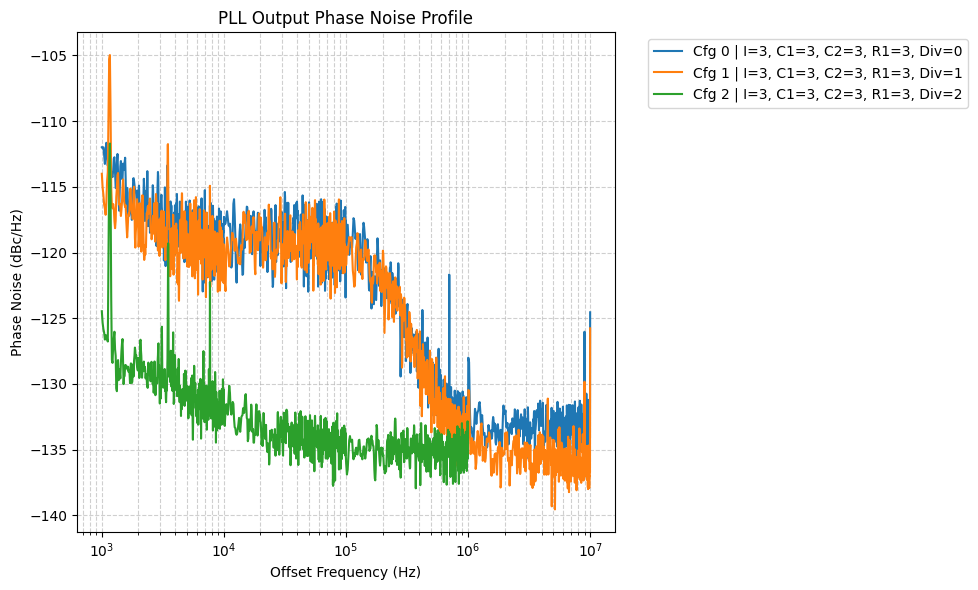

/tmp/ipykernel_2157397/597911633.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='config_label', y='time_jitter_trace_ps', palette='viridis')


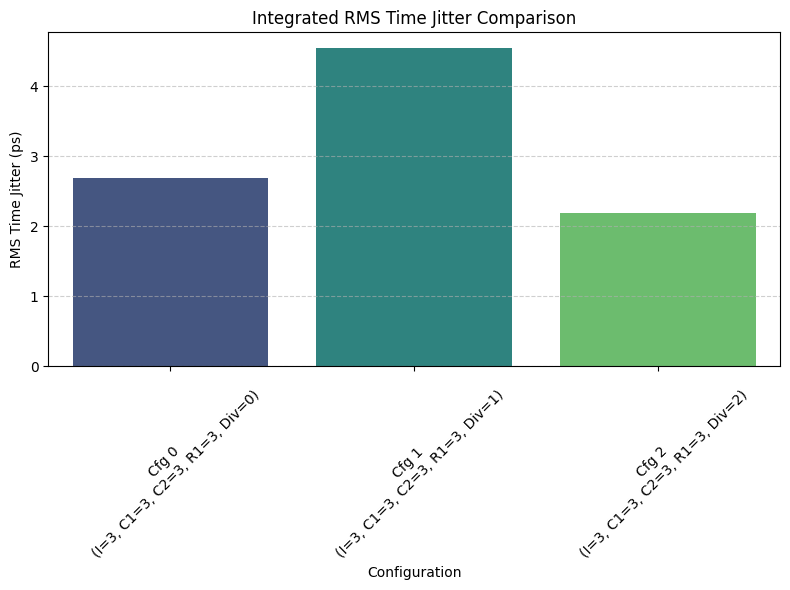

========== RECORD 0 ==========
time                           | 2026-10-12T17:32:42
cfg_idx                        | 0
fb_clk_oen                     | 1
pll_clk_o_en                   | 1
clk_div_val                    | 4
clk_div_en                     | 1
pdown_PD                       | 0
pdown_VCO                      | 0
vco_tune_coarse                | 10
vco_current_min                | 12
vco_current_max                | 13
set_v_ctrl                     | 2
set_clk_out                    | 1
set_div_freq                   | 0
set_fb_mux                     | 0
set_current                    | 3
set_c1                         | 3
set_c2                         | 3
set_r1                         | 3
f_out                          | 75000000.0
f_pll_out                      | 75000000.0
pll_div                        | 1
ext_div                        | 1.0
offset_max                     | 10000000.0
f_out_meas                     | 74999957.5
f_vco_meas                     | 74

In [140]:
display_bypass = True

if display_bypass:
    print(f"Bypass configuration — Divider Variation")

    plot_phase_noise_div(TRACES_BYPASS_CSV)
    plot_jitter_comparison(RESULTS_BYPASS_CSV)
    print_csv_fully_visible(RESULTS_BYPASS_CSV, display_format="list")